# E57 · resultados visibles sin ejecutar celdas

|   Fold |   Mejor época |   Épocas |   AUC val |   AP val |   AUC final |   TN |   FP |   FN |   TP |
|-------:|--------------:|---------:|----------:|---------:|------------:|-----:|-----:|-----:|-----:|
|      0 |            14 |       24 |    0.6703 |   0.4225 |      0.557  |  155 |    0 |   64 |    0 |
|      1 |            27 |       37 |    0.6299 |   0.4108 |      0.5844 |  157 |    0 |   62 |    0 |
|      2 |            10 |       20 |    0.6688 |   0.4006 |      0.5678 |  161 |    0 |   59 |    0 |
|      3 |             2 |       12 |    0.5503 |   0.4161 |      0.449  |  145 |    0 |   75 |    0 |
|      4 |             5 |       15 |    0.5927 |   0.3977 |      0.5474 |  157 |    0 |   62 |    0 |

Los máximos se eligieron usando la validación del propio fold; su media es una descripción optimista, no una estimación exterior independiente. El fold 0 es histórico y los folds 1–4 se ejecutaron después con la misma receta. El umbral se mantuvo fijo en 0,5. Media de los cinco máximos: 0.6224; DE entre folds: 0.0514.

[Protocolo](README.md) · [Notebook principal](../results/RESULTADOS.ipynb).

## E57 · versión con umbral 0,325

|   Fold |    AUC |     AP |   Precisión pCR |   Sensibilidad |   Especificidad |     BA |   F1 macro |   TN |   FP |   FN |   TP |
|-------:|-------:|-------:|----------------:|---------------:|----------------:|-------:|-----------:|-----:|-----:|-----:|-----:|
|      0 | 0.6703 | 0.4225 |          0.439  |         0.5625 |          0.7032 | 0.6329 |     0.6199 |  109 |   46 |   28 |   36 |
|      1 | 0.6299 | 0.4108 |          0.338  |         0.7742 |          0.4013 | 0.5877 |     0.5045 |   63 |   94 |   14 |   48 |
|      2 | 0.6688 | 0.4006 |          0.3272 |         0.8983 |          0.323  | 0.6106 |     0.4773 |   52 |  109 |    6 |   53 |
|      3 | 0.5503 | 0.4161 |          0.5714 |         0.0533 |          0.9793 | 0.5163 |     0.4454 |  142 |    3 |   71 |    4 |
|      4 | 0.5927 | 0.3977 |          0.29   |         0.9355 |          0.0955 | 0.5155 |     0.3066 |   15 |  142 |    4 |   58 |

Conteos de los cinco folds: **TN 381, FP 394, FN 123, TP 199**. Sensibilidad 61.8%; especificidad 49.2%; precisión pCR 33.6%; balanced accuracy 0.5548.

**Cambiar el umbral es válido y no requiere reentrenar.** Aquí 0,325 se ha elegido después de ver estos resultados: esta tabla es exploratoria y no una estimación independiente del rendimiento futuro. La comparación conserva la matriz original a 0,5 y declara cómo se eligió la nueva. Para estimar generalización, fijar el procedimiento de selección usando solo train/validación interna y evaluar en pacientes distintas. El AUC, AP, probabilidades, pesos y curvas por época son los mismos.

Clasificar más positivas también incrementa los falsos positivos. Ningún cambio de umbral puede crear separación entre clases que el modelo no ha aprendido.


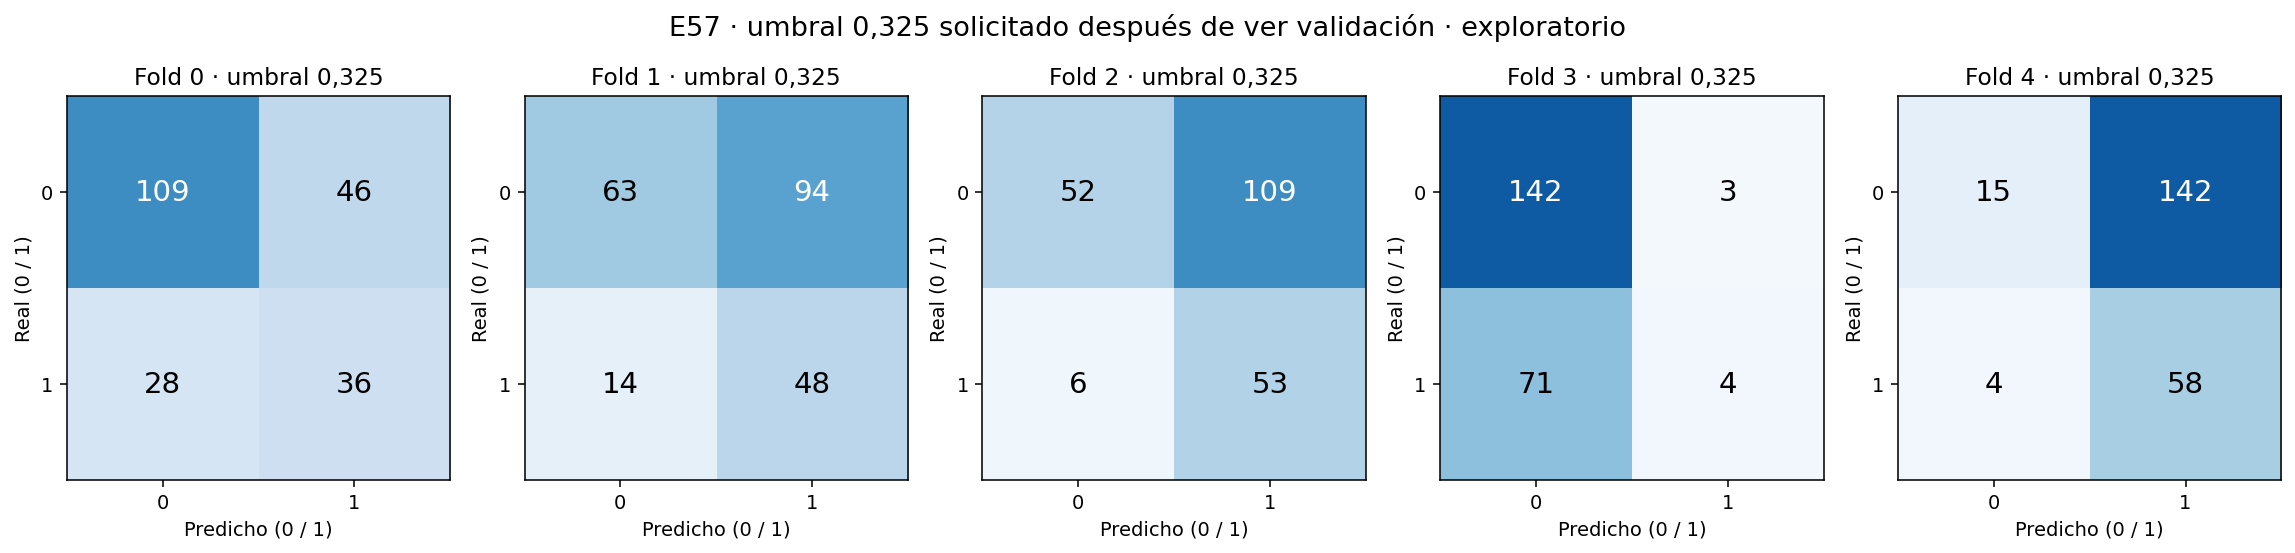

In [1]:
# E57 · matrices con umbral 0,325; vista exploratoria
# Imagen guardada; visible sin ejecutar esta celda.


## Comparación directa de los cuatro folds nuevos

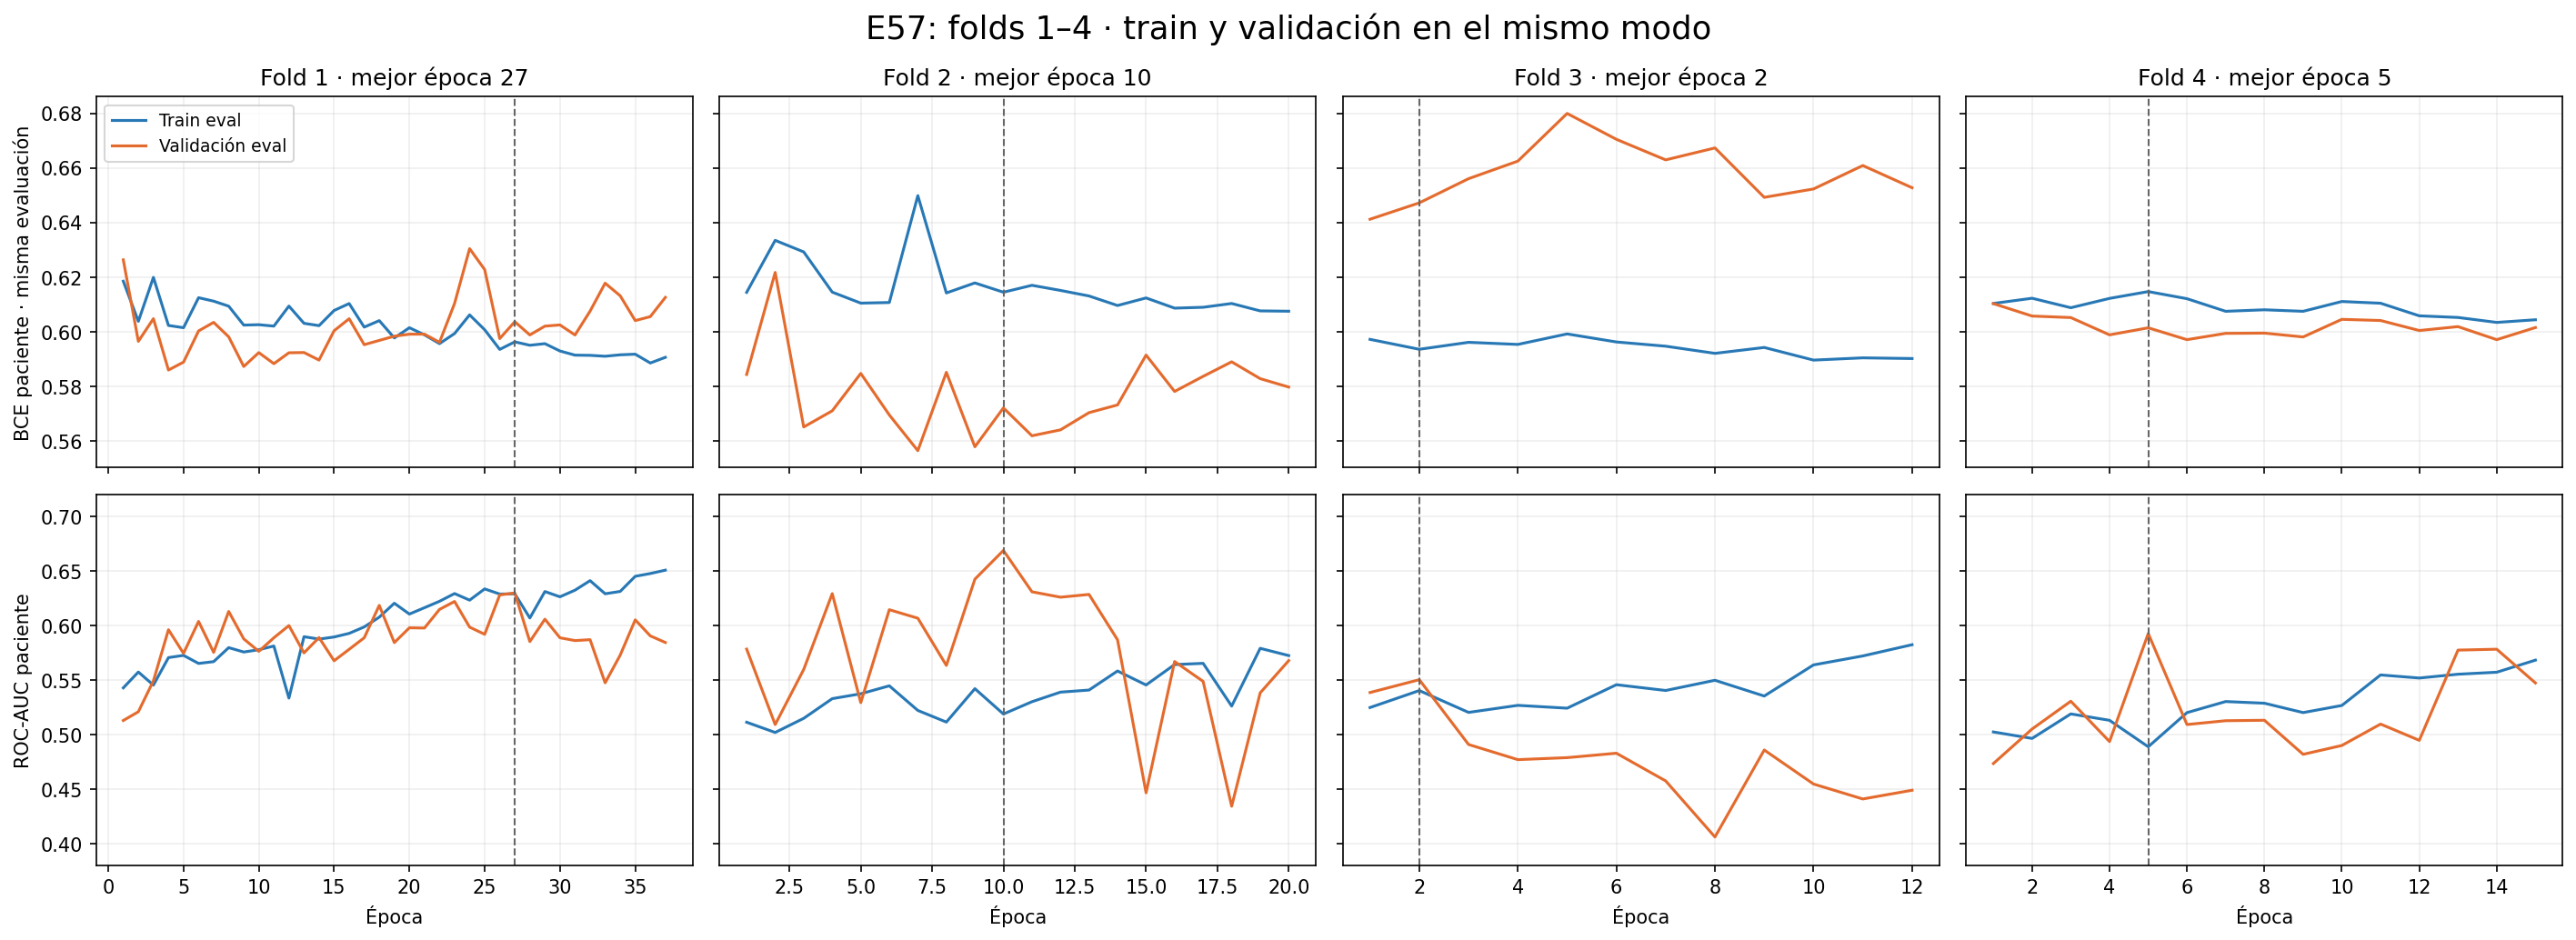

In [1]:
# Panel de BCE y AUC comparables por fold
# Imagen guardada; visible sin ejecutar esta celda.


## E57 · Fold 0 · todas las épocas, gráficas y matriz

Mejor época 14/24. Referencia histórica. La tabla siguiente contiene todas las épocas; después aparecen los seis paneles habituales y el diagnóstico de probabilidades.

Clase,Precisión,Recall,F1,Pacientes
no pCR (0),0.7078,1.0,0.8289,155
pCR (1),0.0000,0.0,0.0000,64


Baseline siempre noPCR: F1macro=0.4144; balancedaccuracy=0,5. Métricas al umbral 0.5, sin ajustarlo aquí.

**E57_patient_feature_mean_mac** · mejor época 14/24 · 219 pacientes · ROC-AUC 0.6703 · AP 0.4225 · precisión 0.0% · sensibilidad 0.0% · F1 0.000

Época,Loss train,Loss validación,ROC-AUC paciente,AP paciente,LR,Segundos
1,0.62179,0.62650,0.54788,0.31282,0.00100,59.96027
2,0.62826,0.60440,0.51673,0.29005,0.00100,58.37244
3,0.61886,0.60180,0.53700,0.29671,0.00100,58.84450
4,0.62324,0.62545,0.50625,0.31459,0.00100,62.36016
5,0.61387,0.61076,0.54284,0.31774,0.00100,67.02071
6,0.61382,0.60939,0.53438,0.31149,0.00050,64.22783
7,0.61162,0.59599,0.55514,0.31898,0.00050,63.92076
8,0.60743,0.59922,0.56139,0.33609,0.00050,69.50052
9,0.61149,0.59868,0.59113,0.38318,0.00050,65.52199
10,0.61212,0.59546,0.58296,0.37678,0.00050,64.65094


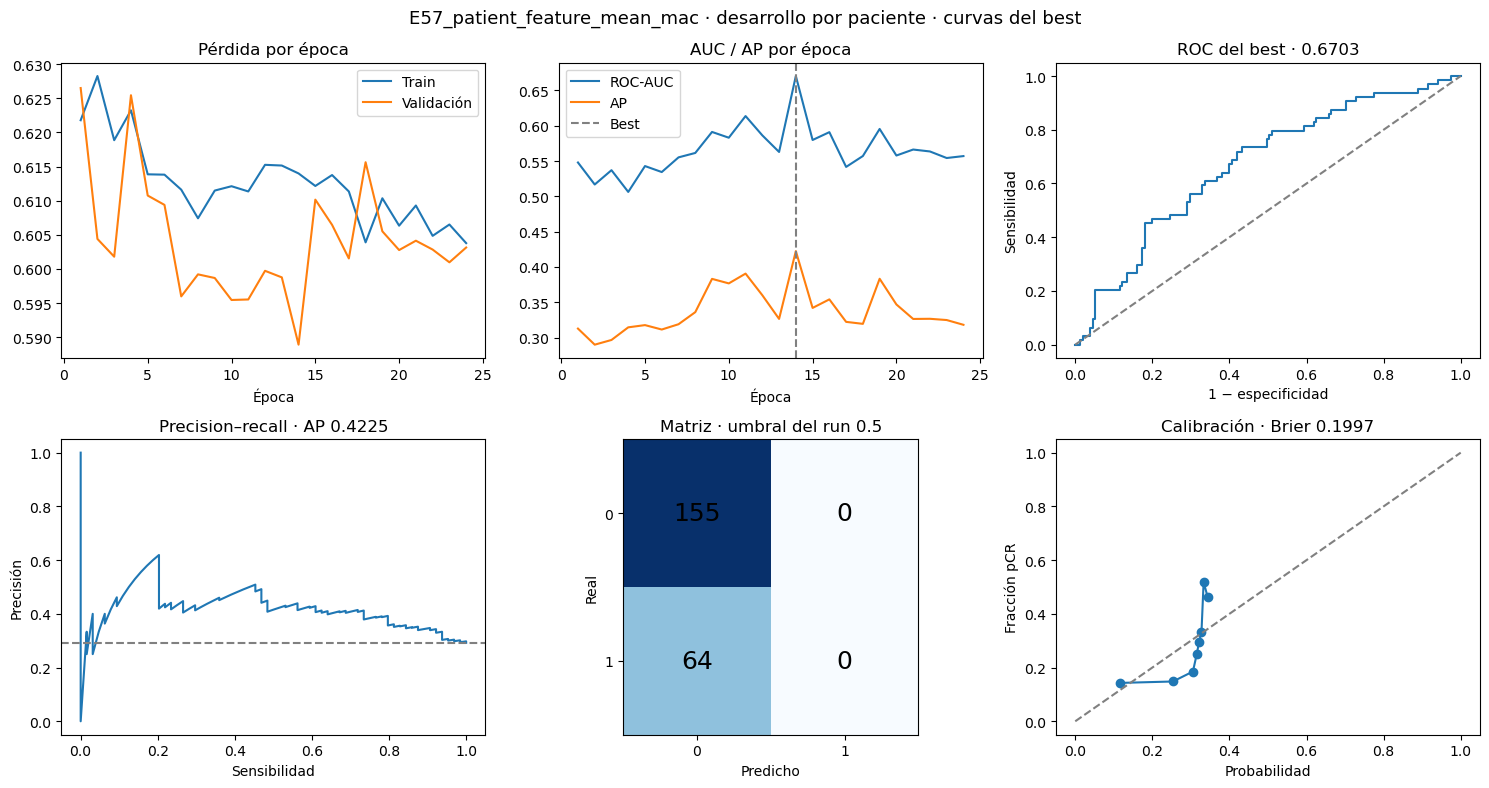

**Diagnóstico de la matriz y precisión · sin umbral adoptado.** A 0,5 hay 0 predicciones positivas de 219 pacientes. Probabilidad máxima: 0.360. Media no-pCR: 0.280; media pCR: 0.311. Proporción pCR: 29.2%, referencia de precisión sin discriminación. Cuando no se predicen positivas, la precisión de pCR no está definida; el resumen histórico la representa como cero por convención. La siguiente tabla explora umbrales fijos sobre validación ya utilizada para seleccionar el checkpoint. No es rendimiento independiente ni elige un umbral final; cambiar umbral no mejora AUC ni AP. Bajar umbral intercambia FN por FP.

Umbral,Positivas predichas,Precisión pCR,Sensibilidad,Especificidad,F1 macro,Balanced accuracy,TP,FN,FP,TN
0.250,180,0.333,0.938,0.226,0.426,0.582,60,4,120,35
0.300,156,0.346,0.844,0.342,0.489,0.593,54,10,102,53
0.325,82,0.439,0.562,0.703,0.620,0.633,36,28,46,109
0.350,4,0.250,0.016,0.981,0.426,0.498,1,63,3,152
0.400,0,No definida,0.000,1.000,0.414,0.500,0,64,0,155
0.425,0,No definida,0.000,1.000,0.414,0.500,0,64,0,155
0.450,0,No definida,0.000,1.000,0.414,0.500,0,64,0,155
0.500,0,No definida,0.000,1.000,0.414,0.500,0,64,0,155


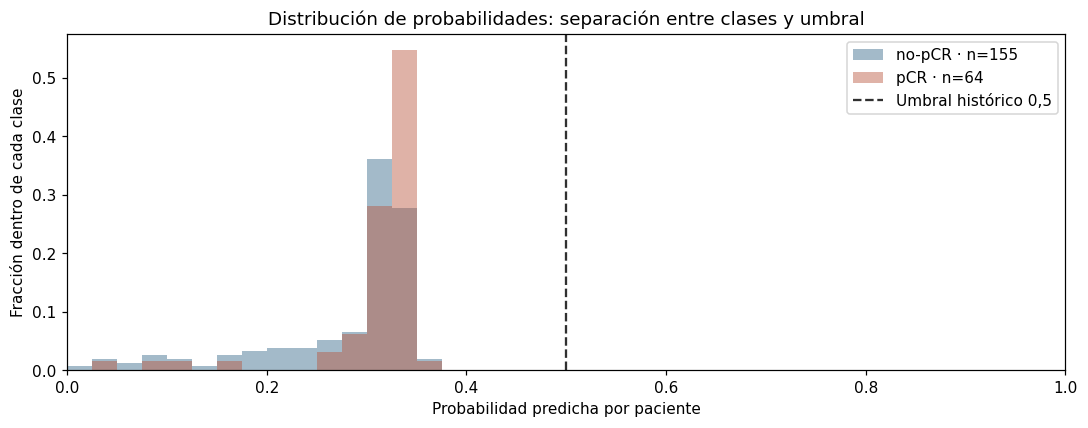

In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'app.py').is_file())
if str(root) not in sys.path: sys.path.insert(0,str(root))
from src.reporting.clear_results import show_run
from src.reporting.balanced_results import class_table
from src.evaluation.decision_diagnostics import display_decision
folder=root/'reports/patient_features/E57_patient_feature_mean_mac/fold_0_seed_42'
summary=json.loads((folder/'summary.json').read_text())
display(class_table(summary['validation_metrics']['patient']))
show_run(folder,summary)
display_decision(folder)
if (folder/'curvas_comparables.png').exists():
    display(Image(filename=str(folder/'curvas_comparables.png')))


## E57 · Fold 1 · todas las épocas, gráficas y matriz

Mejor época 27/37. La tabla siguiente contiene todas las épocas; después aparecen los seis paneles habituales y el diagnóstico de probabilidades.

Clase,Precisión,Recall,F1,Pacientes
no pCR (0),0.7169,1.0,0.8351,157
pCR (1),0.0000,0.0,0.0000,62


Baseline siempre noPCR: F1macro=0.4176; balancedaccuracy=0,5. Métricas al umbral 0.5, sin ajustarlo aquí.

**E57_estabilidad_f1** · mejor época 27/37 · 219 pacientes · ROC-AUC 0.6299 · AP 0.4108 · precisión 0.0% · sensibilidad 0.0% · F1 0.000

Época,Loss train,Loss validación,ROC-AUC paciente,AP paciente,LR,Segundos
1,0.62181,0.62632,0.51294,0.32112,0.00100,96.35844
2,0.62227,0.59647,0.52096,0.32798,0.00100,96.36275
3,0.61727,0.60476,0.54931,0.30156,0.00100,96.03310
4,0.61544,0.58595,0.59616,0.39293,0.00100,95.99872
5,0.62269,0.58885,0.57448,0.36536,0.00100,96.01606
6,0.60898,0.60028,0.60376,0.36064,0.00100,95.65430
7,0.61389,0.60341,0.57541,0.37791,0.00100,96.08238
8,0.61237,0.59812,0.61290,0.39394,0.00100,95.78663
9,0.61194,0.58724,0.58773,0.39719,0.00100,95.66528
10,0.61683,0.59234,0.57633,0.37402,0.00100,95.84681


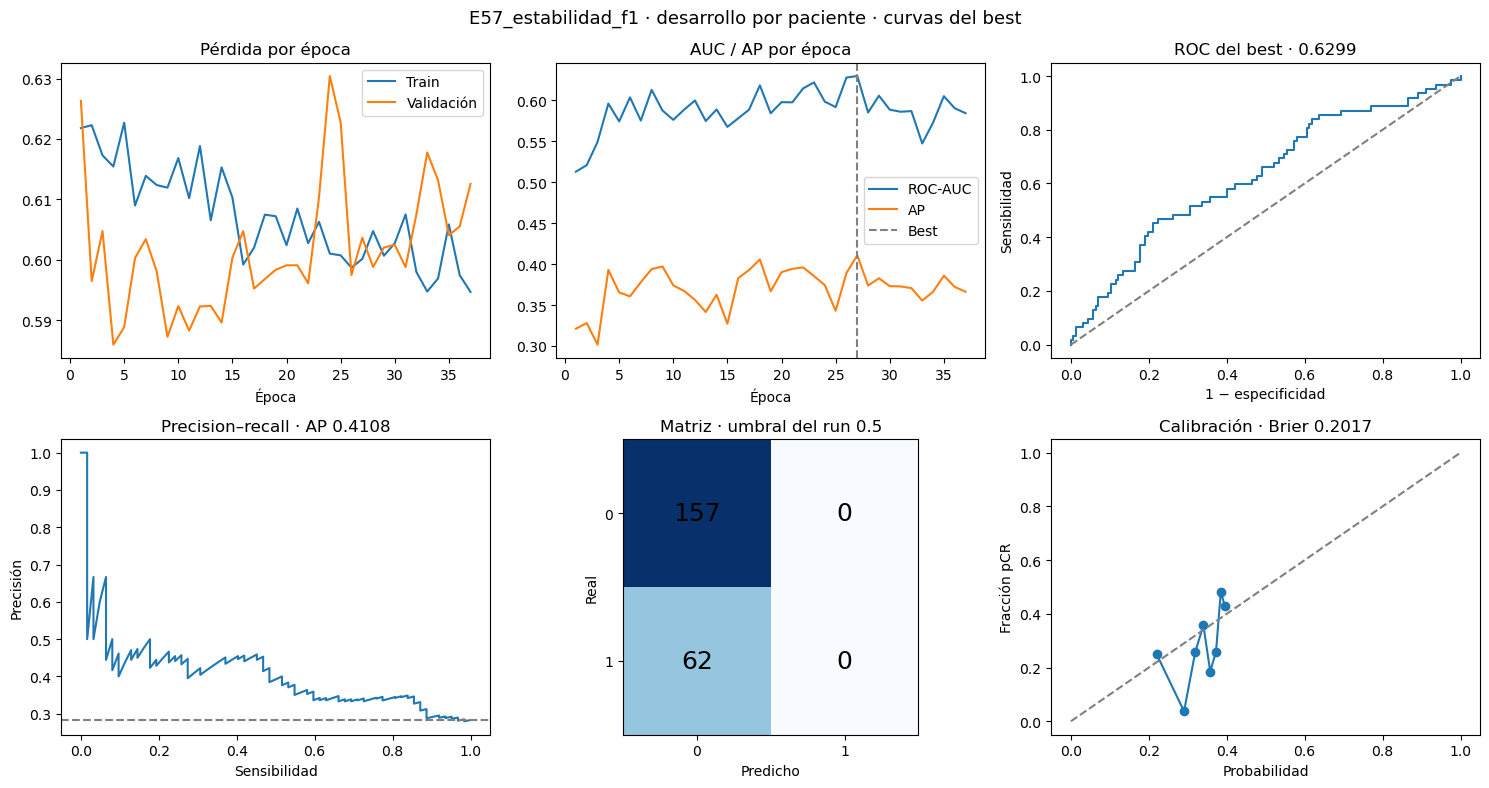

**Diagnóstico de la matriz y precisión · sin umbral adoptado.** A 0,5 hay 0 predicciones positivas de 219 pacientes. Probabilidad máxima: 0.410. Media no-pCR: 0.330; media pCR: 0.348. Proporción pCR: 28.3%, referencia de precisión sin discriminación. Cuando no se predicen positivas, la precisión de pCR no está definida; el resumen histórico la representa como cero por convención. La siguiente tabla explora umbrales fijos sobre validación ya utilizada para seleccionar el checkpoint. No es rendimiento independiente ni elige un umbral final; cambiar umbral no mejora AUC ni AP. Bajar umbral intercambia FN por FP.

Umbral,Positivas predichas,Precisión pCR,Sensibilidad,Especificidad,F1 macro,Balanced accuracy,TP,FN,FP,TN
0.250,200,0.290,0.935,0.096,0.307,0.516,58,4,142,15
0.300,171,0.316,0.871,0.255,0.427,0.563,54,8,117,40
0.325,142,0.338,0.774,0.401,0.505,0.588,48,14,94,63
0.350,110,0.336,0.597,0.535,0.531,0.566,37,25,73,84
0.400,3,0.667,0.032,0.994,0.449,0.513,2,60,1,156
0.425,0,No definida,0.000,1.000,0.418,0.500,0,62,0,157
0.450,0,No definida,0.000,1.000,0.418,0.500,0,62,0,157
0.500,0,No definida,0.000,1.000,0.418,0.500,0,62,0,157


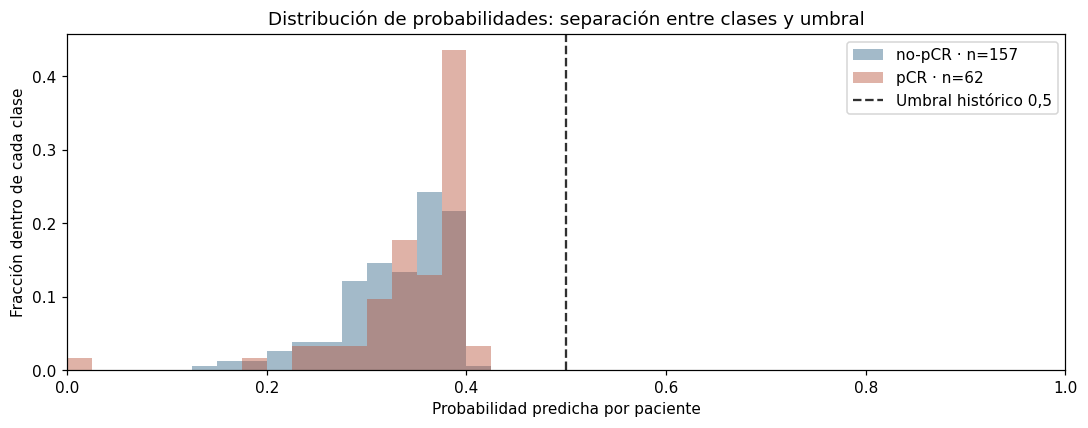

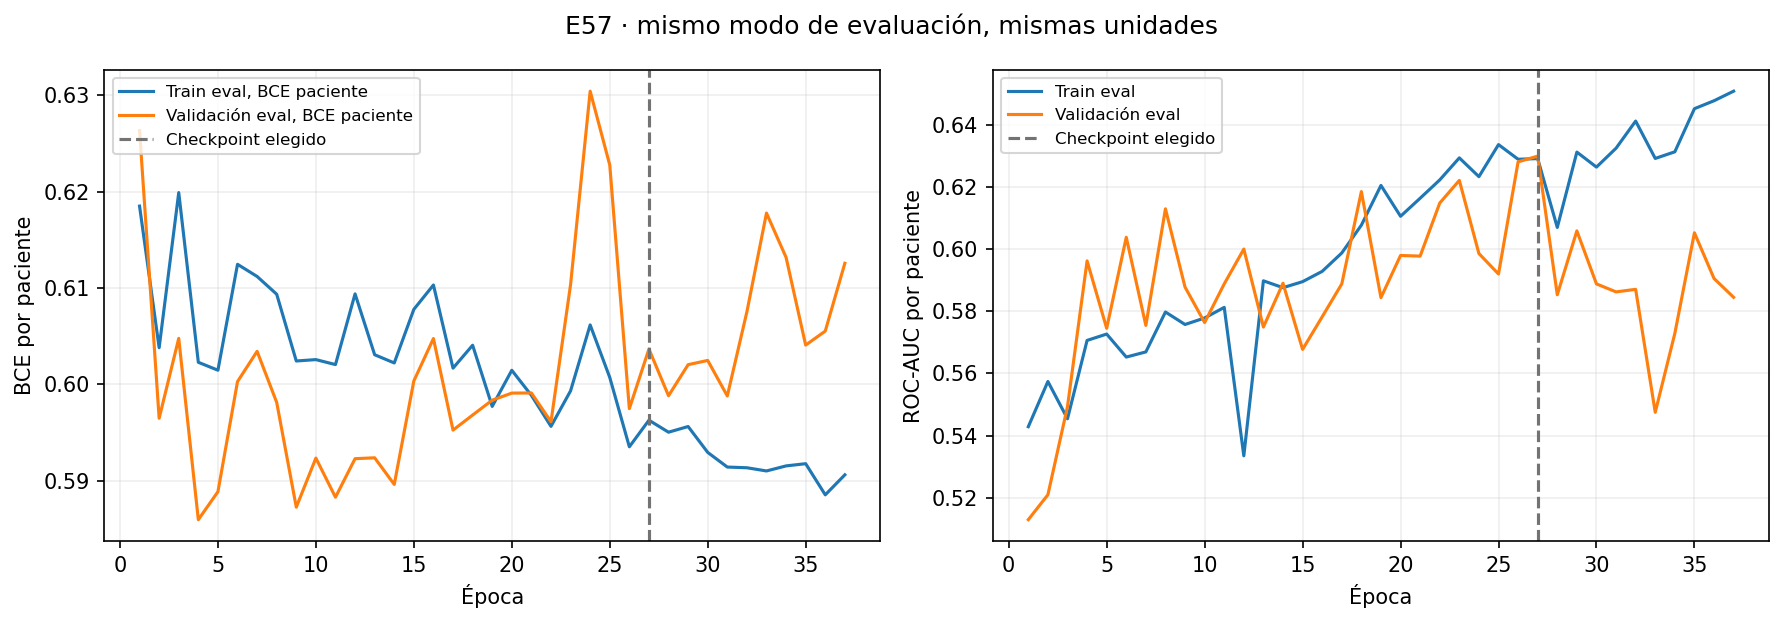

In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'app.py').is_file())
if str(root) not in sys.path: sys.path.insert(0,str(root))
from src.reporting.clear_results import show_run
from src.reporting.balanced_results import class_table
from src.evaluation.decision_diagnostics import display_decision
folder=root/'experiments/E57_patient_feature_mean_mac/stability/resultados/fold_1_seed_42'
summary=json.loads((folder/'summary.json').read_text())
display(class_table(summary['validation_metrics']['patient']))
show_run(folder,summary)
display_decision(folder)
if (folder/'curvas_comparables.png').exists():
    display(Image(filename=str(folder/'curvas_comparables.png')))


## E57 · Fold 2 · todas las épocas, gráficas y matriz

Mejor época 10/20. La tabla siguiente contiene todas las épocas; después aparecen los seis paneles habituales y el diagnóstico de probabilidades.

Clase,Precisión,Recall,F1,Pacientes
no pCR (0),0.7318,1.0,0.8451,161
pCR (1),0.0000,0.0,0.0000,59


Baseline siempre noPCR: F1macro=0.4226; balancedaccuracy=0,5. Métricas al umbral 0.5, sin ajustarlo aquí.

**E57_estabilidad_f2** · mejor época 10/20 · 220 pacientes · ROC-AUC 0.6688 · AP 0.4006 · precisión 0.0% · sensibilidad 0.0% · F1 0.000

Época,Loss train,Loss validación,ROC-AUC paciente,AP paciente,LR,Segundos
1,0.63061,0.58432,0.57838,0.31474,0.00100,96.61535
2,0.63633,0.62170,0.50921,0.30237,0.00100,94.79168
3,0.62880,0.56510,0.55974,0.27773,0.00100,95.64869
4,0.61507,0.57101,0.62922,0.33921,0.00100,97.78311
5,0.62313,0.58471,0.52932,0.28509,0.00100,100.68328
6,0.61898,0.56950,0.61449,0.35489,0.00100,101.25647
7,0.62157,0.55642,0.60670,0.40270,0.00100,101.78259
8,0.61731,0.58512,0.56343,0.34517,0.00100,101.07944
9,0.61339,0.55784,0.64249,0.38825,0.00050,101.58285
10,0.62521,0.57207,0.66881,0.40060,0.00050,102.12736


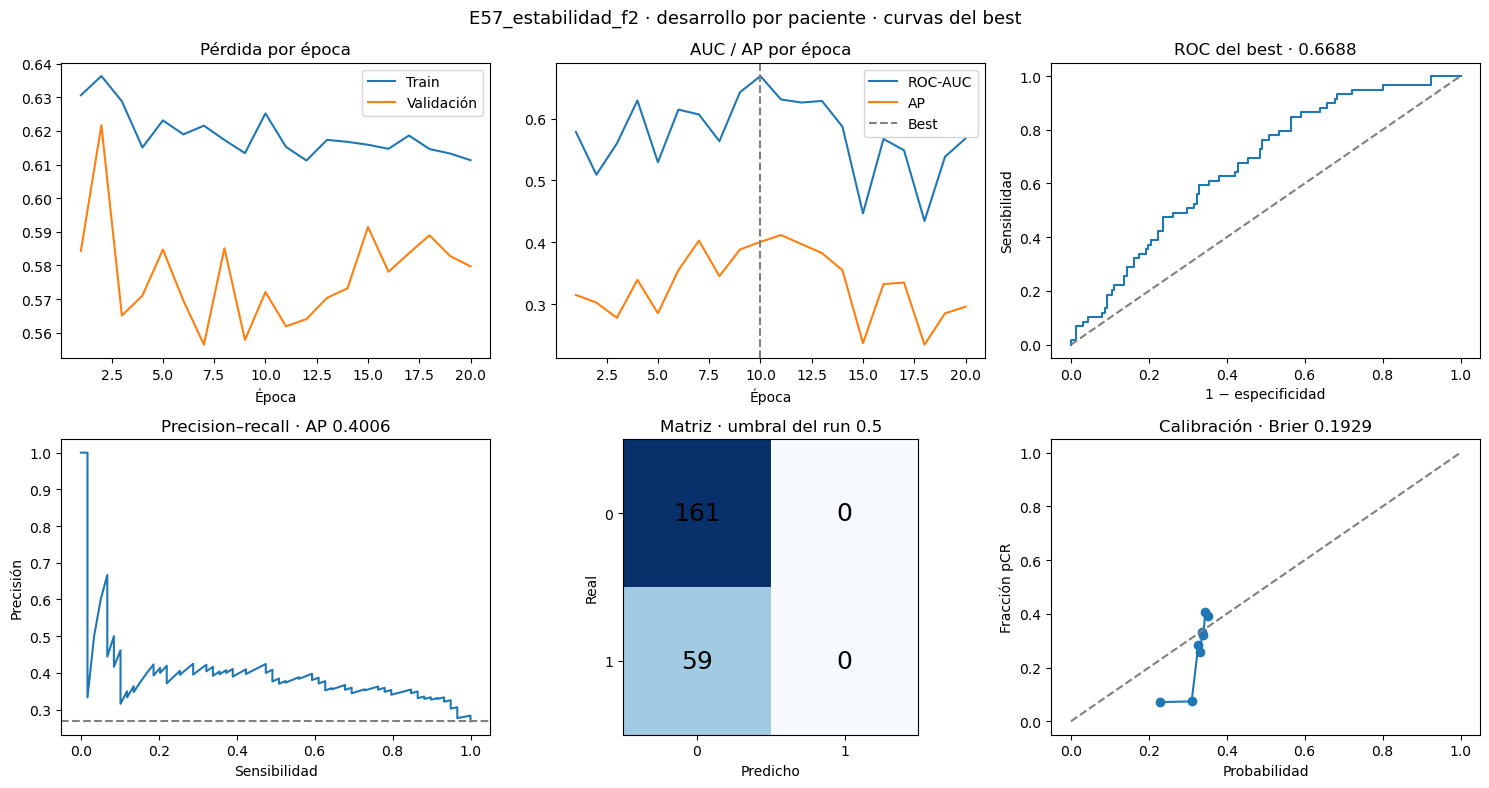

**Diagnóstico de la matriz y precisión · sin umbral adoptado.** A 0,5 hay 0 predicciones positivas de 220 pacientes. Probabilidad máxima: 0.366. Media no-pCR: 0.316; media pCR: 0.336. Proporción pCR: 26.8%, referencia de precisión sin discriminación. Cuando no se predicen positivas, la precisión de pCR no está definida; el resumen histórico la representa como cero por convención. La siguiente tabla explora umbrales fijos sobre validación ya utilizada para seleccionar el checkpoint. No es rendimiento independiente ni elige un umbral final; cambiar umbral no mejora AUC ni AP. Bajar umbral intercambia FN por FP.

Umbral,Positivas predichas,Precisión pCR,Sensibilidad,Especificidad,F1 macro,Balanced accuracy,TP,FN,FP,TN
0.250,206,0.277,0.966,0.075,0.284,0.520,57,2,149,12
0.300,188,0.303,0.966,0.186,0.386,0.576,57,2,131,30
0.325,162,0.327,0.898,0.323,0.477,0.611,53,6,109,52
0.350,21,0.333,0.119,0.913,0.496,0.516,7,52,14,147
0.400,0,No definida,0.000,1.000,0.423,0.500,0,59,0,161
0.425,0,No definida,0.000,1.000,0.423,0.500,0,59,0,161
0.450,0,No definida,0.000,1.000,0.423,0.500,0,59,0,161
0.500,0,No definida,0.000,1.000,0.423,0.500,0,59,0,161


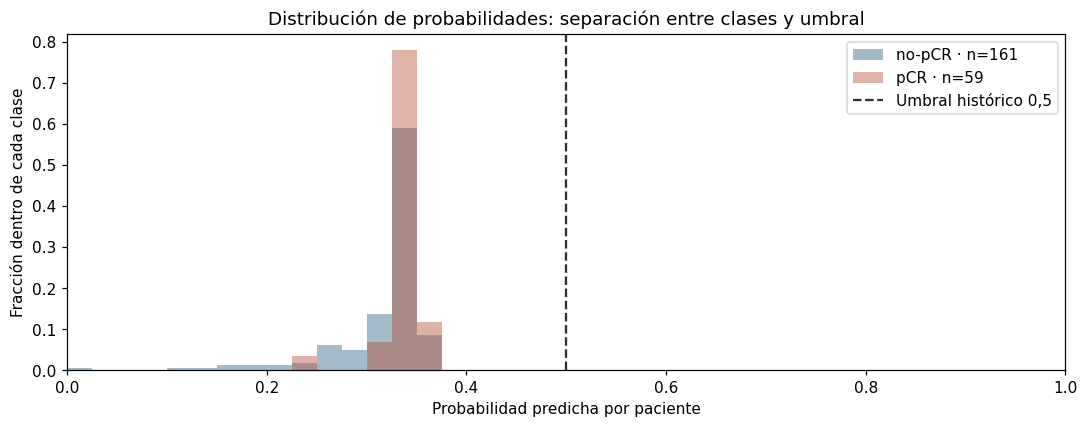

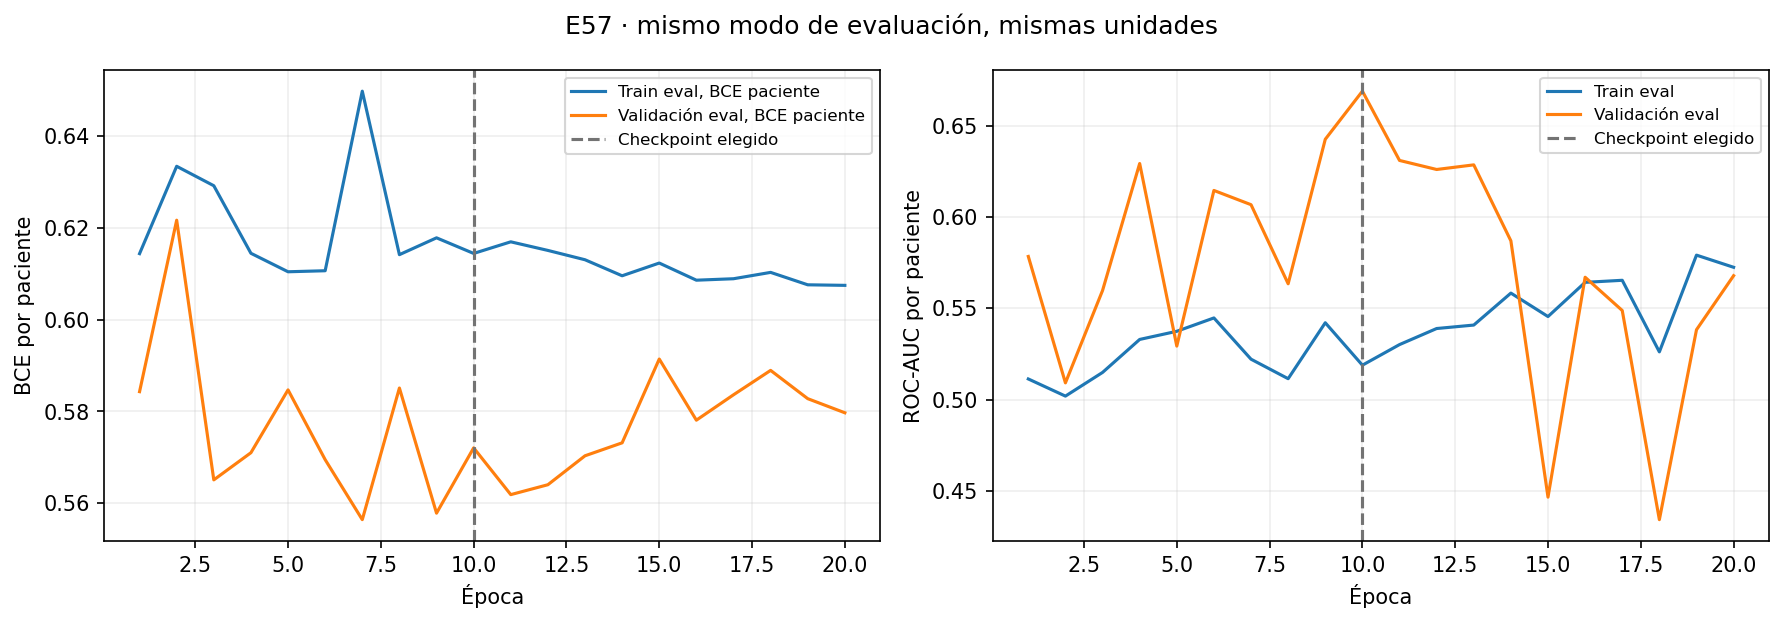

In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'app.py').is_file())
if str(root) not in sys.path: sys.path.insert(0,str(root))
from src.reporting.clear_results import show_run
from src.reporting.balanced_results import class_table
from src.evaluation.decision_diagnostics import display_decision
folder=root/'experiments/E57_patient_feature_mean_mac/stability/resultados/fold_2_seed_42'
summary=json.loads((folder/'summary.json').read_text())
display(class_table(summary['validation_metrics']['patient']))
show_run(folder,summary)
display_decision(folder)
if (folder/'curvas_comparables.png').exists():
    display(Image(filename=str(folder/'curvas_comparables.png')))


## E57 · Fold 3 · todas las épocas, gráficas y matriz

Mejor época 2/12. La tabla siguiente contiene todas las épocas; después aparecen los seis paneles habituales y el diagnóstico de probabilidades.

Clase,Precisión,Recall,F1,Pacientes
no pCR (0),0.6591,1.0,0.7945,145
pCR (1),0.0000,0.0,0.0000,75


Baseline siempre noPCR: F1macro=0.3973; balancedaccuracy=0,5. Métricas al umbral 0.5, sin ajustarlo aquí.

**E57_estabilidad_f3** · mejor época 2/12 · 220 pacientes · ROC-AUC 0.5503 · AP 0.4161 · precisión 0.0% · sensibilidad 0.0% · F1 0.000

Época,Loss train,Loss validación,ROC-AUC paciente,AP paciente,LR,Segundos
1,0.61698,0.64118,0.53857,0.40808,0.00100,100.34781
2,0.61400,0.64718,0.55034,0.41611,0.00100,101.86870
3,0.60616,0.65604,0.49094,0.31779,0.00100,102.33850
4,0.61297,0.66247,0.47706,0.33263,0.00100,102.46771
5,0.60847,0.67993,0.47890,0.32447,0.00100,106.25378
6,0.60039,0.67045,0.48294,0.35122,0.00100,104.89481
7,0.59828,0.66293,0.45756,0.31892,0.00050,102.79756
8,0.59944,0.66730,0.40616,0.28329,0.00050,101.98171
9,0.60852,0.64920,0.48589,0.32897,0.00050,101.65322
10,0.60535,0.65227,0.45471,0.31218,0.00050,101.92241


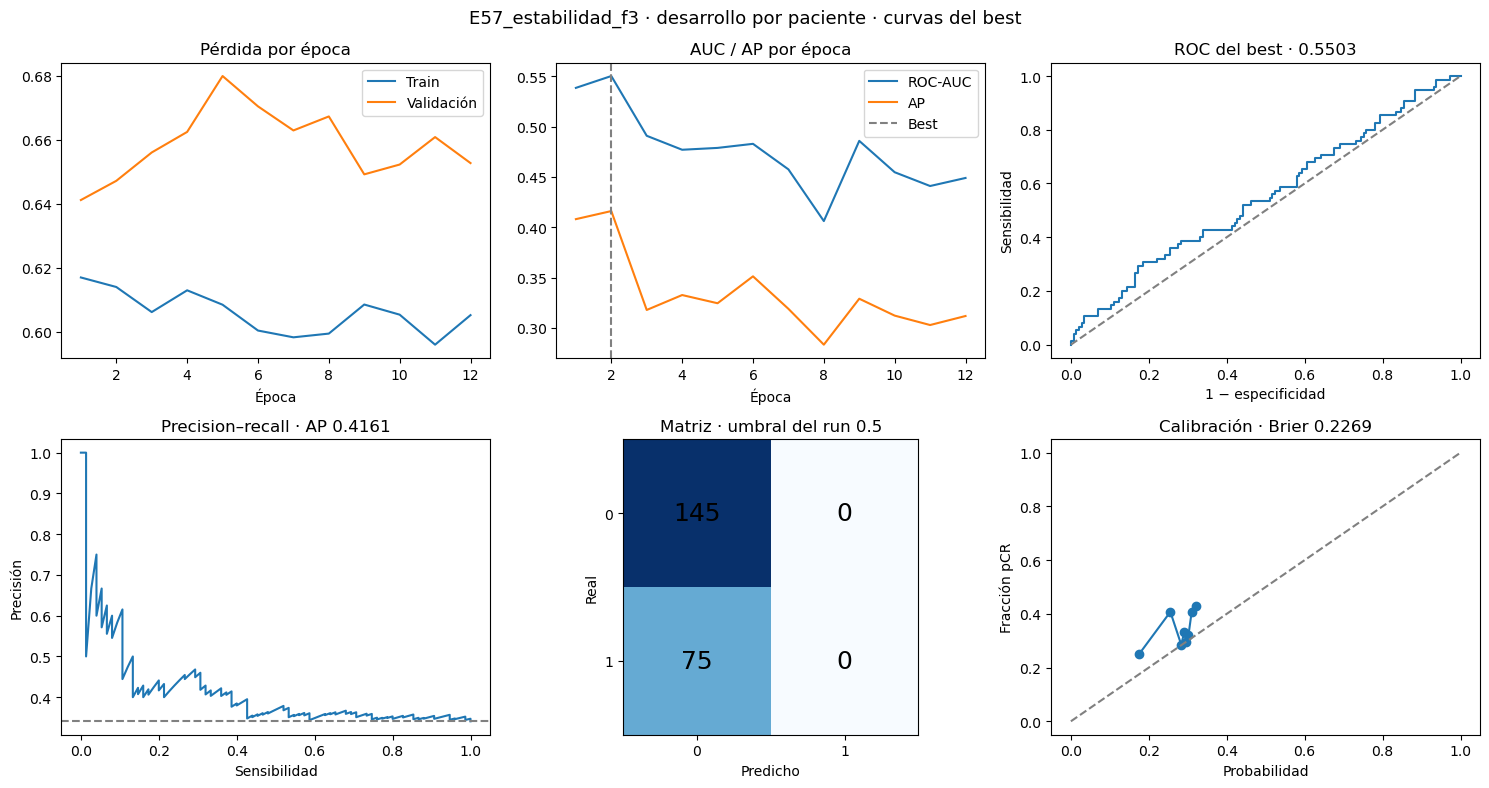

**Diagnóstico de la matriz y precisión · sin umbral adoptado.** A 0,5 hay 0 predicciones positivas de 220 pacientes. Probabilidad máxima: 0.343. Media no-pCR: 0.276; media pCR: 0.285. Proporción pCR: 34.1%, referencia de precisión sin discriminación. Cuando no se predicen positivas, la precisión de pCR no está definida; el resumen histórico la representa como cero por convención. La siguiente tabla explora umbrales fijos sobre validación ya utilizada para seleccionar el checkpoint. No es rendimiento independiente ni elige un umbral final; cambiar umbral no mejora AUC ni AP. Bajar umbral intercambia FN por FP.

Umbral,Positivas predichas,Precisión pCR,Sensibilidad,Especificidad,F1 macro,Balanced accuracy,TP,FN,FP,TN
0.250,183,0.350,0.853,0.179,0.391,0.516,64,11,119,26
0.300,79,0.380,0.400,0.662,0.530,0.531,30,45,49,96
0.325,7,0.571,0.053,0.979,0.445,0.516,4,71,3,142
0.350,0,No definida,0.000,1.000,0.397,0.500,0,75,0,145
0.400,0,No definida,0.000,1.000,0.397,0.500,0,75,0,145
0.425,0,No definida,0.000,1.000,0.397,0.500,0,75,0,145
0.450,0,No definida,0.000,1.000,0.397,0.500,0,75,0,145
0.500,0,No definida,0.000,1.000,0.397,0.500,0,75,0,145


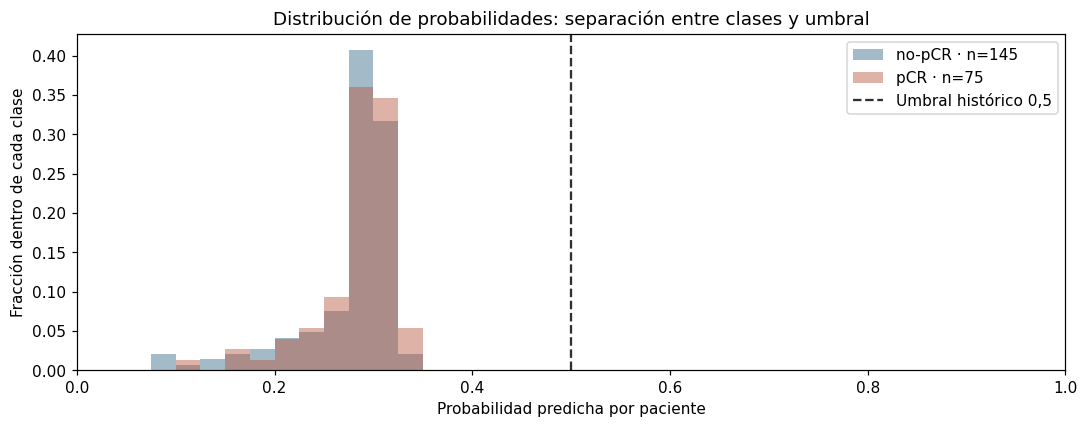

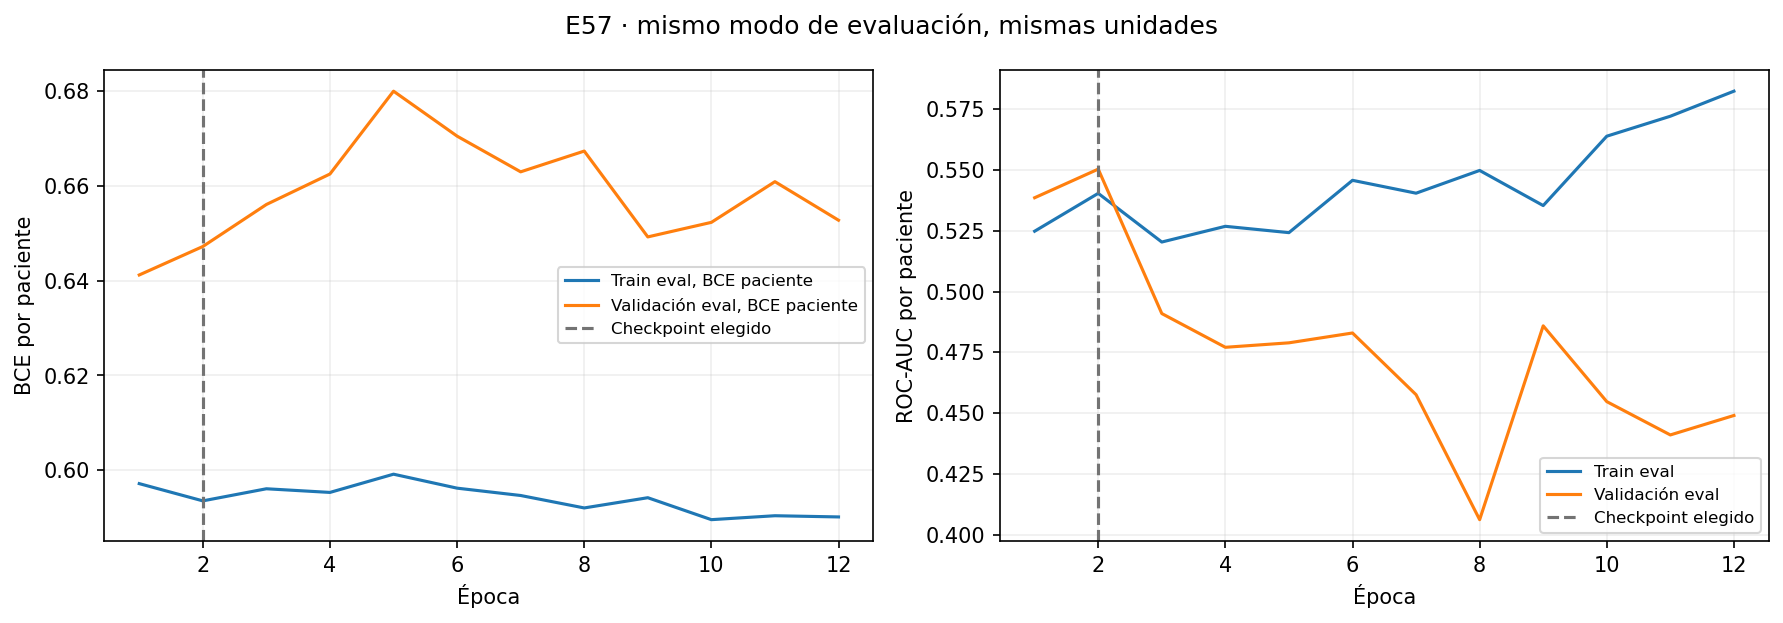

In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'app.py').is_file())
if str(root) not in sys.path: sys.path.insert(0,str(root))
from src.reporting.clear_results import show_run
from src.reporting.balanced_results import class_table
from src.evaluation.decision_diagnostics import display_decision
folder=root/'experiments/E57_patient_feature_mean_mac/stability/resultados/fold_3_seed_42'
summary=json.loads((folder/'summary.json').read_text())
display(class_table(summary['validation_metrics']['patient']))
show_run(folder,summary)
display_decision(folder)
if (folder/'curvas_comparables.png').exists():
    display(Image(filename=str(folder/'curvas_comparables.png')))


## E57 · Fold 4 · todas las épocas, gráficas y matriz

Mejor época 5/15. La tabla siguiente contiene todas las épocas; después aparecen los seis paneles habituales y el diagnóstico de probabilidades.

Clase,Precisión,Recall,F1,Pacientes
no pCR (0),0.7169,1.0,0.8351,157
pCR (1),0.0000,0.0,0.0000,62


Baseline siempre noPCR: F1macro=0.4176; balancedaccuracy=0,5. Métricas al umbral 0.5, sin ajustarlo aquí.

**E57_estabilidad_f4** · mejor época 5/15 · 219 pacientes · ROC-AUC 0.5927 · AP 0.3977 · precisión 0.0% · sensibilidad 0.0% · F1 0.000

Época,Loss train,Loss validación,ROC-AUC paciente,AP paciente,LR,Segundos
1,0.63087,0.61028,0.47349,0.27869,0.00100,99.78365
2,0.62818,0.60573,0.50514,0.27937,0.00100,100.73042
3,0.61455,0.60517,0.53061,0.32510,0.00100,101.04429
4,0.61856,0.59883,0.49363,0.30659,0.00100,100.76933
5,0.62106,0.60142,0.59266,0.39774,0.00100,102.82766
6,0.61126,0.59708,0.50925,0.31213,0.00100,101.41868
7,0.61666,0.59939,0.51274,0.33192,0.00100,101.48990
8,0.62229,0.59947,0.51315,0.33661,0.00100,101.74681
9,0.61761,0.59807,0.48192,0.29691,0.00100,102.78624
10,0.61186,0.60452,0.49003,0.29178,0.00050,101.45805


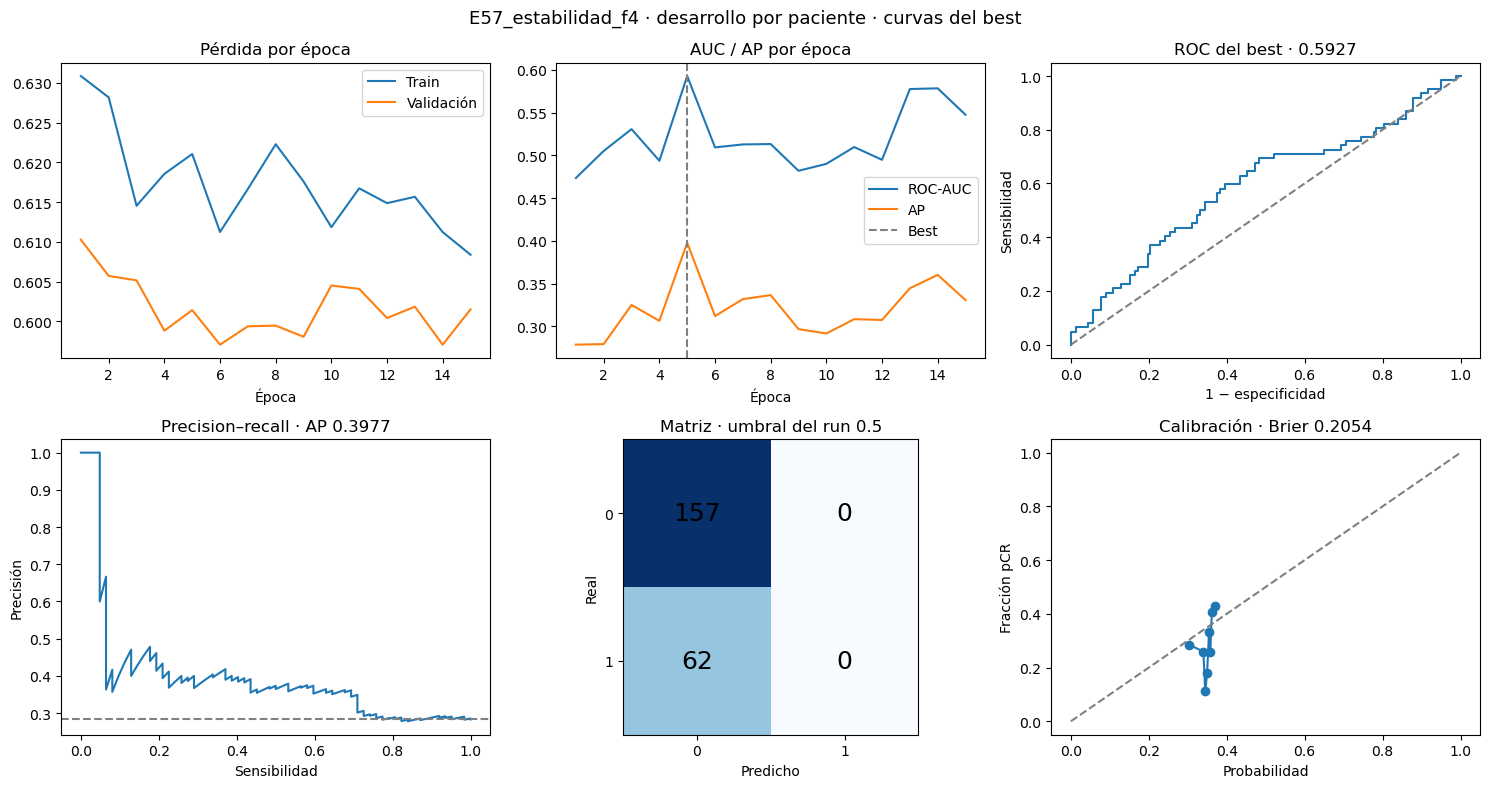

**Diagnóstico de la matriz y precisión · sin umbral adoptado.** A 0,5 hay 0 predicciones positivas de 219 pacientes. Probabilidad máxima: 0.383. Media no-pCR: 0.346; media pCR: 0.352. Proporción pCR: 28.3%, referencia de precisión sin discriminación. Cuando no se predicen positivas, la precisión de pCR no está definida; el resumen histórico la representa como cero por convención. La siguiente tabla explora umbrales fijos sobre validación ya utilizada para seleccionar el checkpoint. No es rendimiento independiente ni elige un umbral final; cambiar umbral no mejora AUC ni AP. Bajar umbral intercambia FN por FP.

Umbral,Positivas predichas,Precisión pCR,Sensibilidad,Especificidad,F1 macro,Balanced accuracy,TP,FN,FP,TN
0.250,217,0.286,1.000,0.013,0.235,0.506,62,0,155,2
0.300,207,0.285,0.952,0.057,0.273,0.504,59,3,148,9
0.325,200,0.290,0.935,0.096,0.307,0.516,58,4,142,15
0.350,121,0.355,0.694,0.503,0.545,0.598,43,19,78,79
0.400,0,No definida,0.000,1.000,0.418,0.500,0,62,0,157
0.425,0,No definida,0.000,1.000,0.418,0.500,0,62,0,157
0.450,0,No definida,0.000,1.000,0.418,0.500,0,62,0,157
0.500,0,No definida,0.000,1.000,0.418,0.500,0,62,0,157


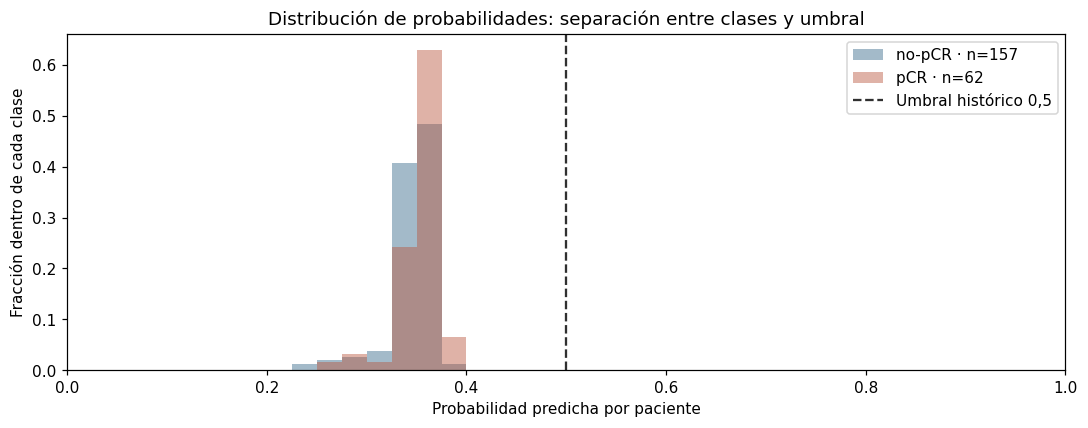

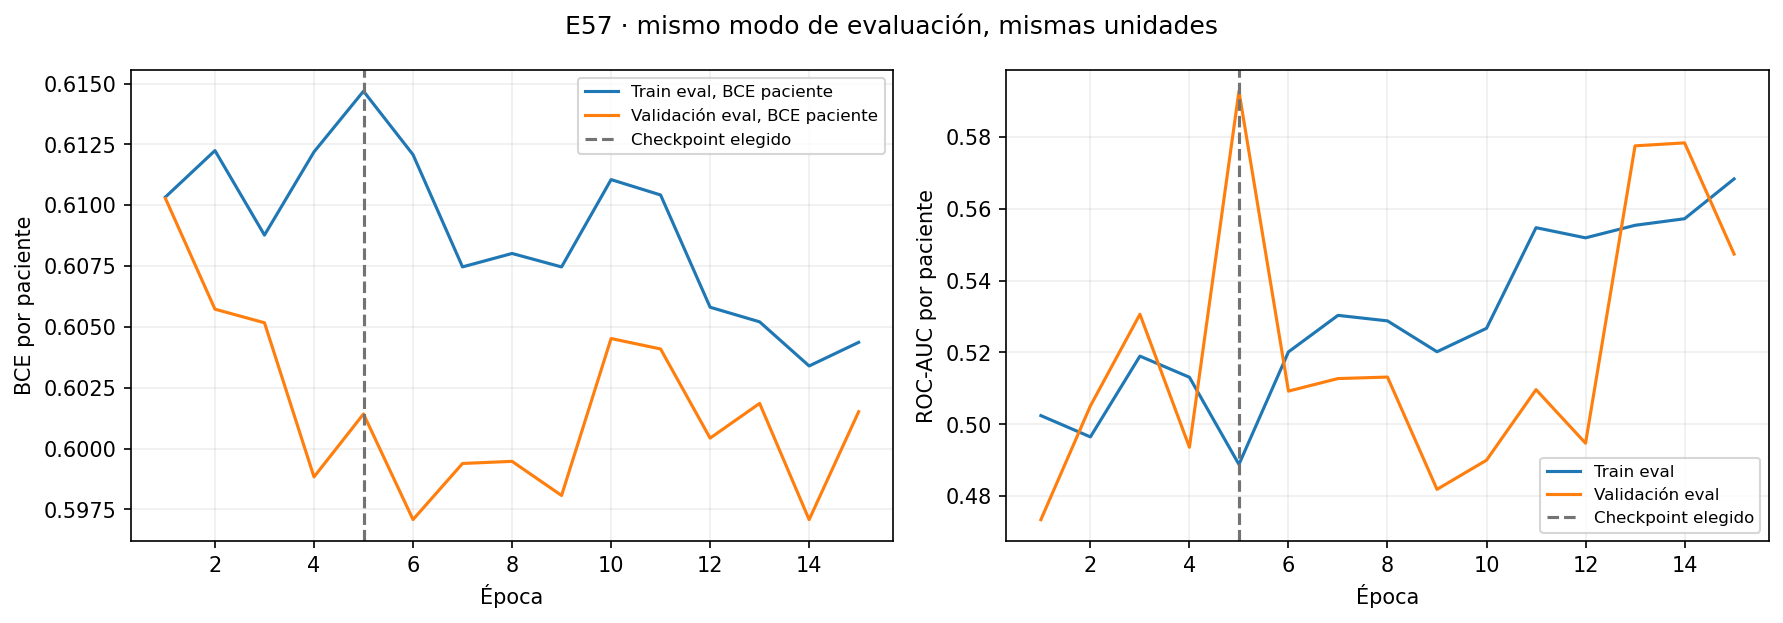

In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src').is_dir() and (p/'app.py').is_file())
if str(root) not in sys.path: sys.path.insert(0,str(root))
from src.reporting.clear_results import show_run
from src.reporting.balanced_results import class_table
from src.evaluation.decision_diagnostics import display_decision
folder=root/'experiments/E57_patient_feature_mean_mac/stability/resultados/fold_4_seed_42'
summary=json.loads((folder/'summary.json').read_text())
display(class_table(summary['validation_metrics']['patient']))
show_run(folder,summary)
display_decision(folder)
if (folder/'curvas_comparables.png').exists():
    display(Image(filename=str(folder/'curvas_comparables.png')))


## Por qué la matriz tiene ceros en la columna positiva

|   Fold |   pCR reales |   Prob. mínima |   Prob. media |   Prob. máxima |   Predicciones positivas a 0,5 |
|-------:|-------------:|---------------:|--------------:|---------------:|-------------------------------:|
|      0 |           64 |         0.0093 |        0.289  |         0.3595 |                              0 |
|      1 |           62 |         0.008  |        0.3348 |         0.4097 |                              0 |
|      2 |           59 |         0.0116 |        0.3213 |         0.3663 |                              0 |
|      3 |           75 |         0.0844 |        0.2792 |         0.3433 |                              0 |
|      4 |           62 |         0.2352 |        0.3477 |         0.3826 |                              0 |

La matriz y la media de probabilidades por paciente se han recalculado y coinciden con los ficheros originales. Todas las probabilidades están por debajo de 0,5: con ese umbral todas las pacientes se clasifican como 0. Esto no prueba por sí solo un error de software ni mala calibración; con prevalencia cercana al 29 % y señal limitada puede ocurrir incluso con probabilidades razonables.

Las matrices siguientes usan 0,5 y dos umbrales fijos que ya figuraban en el diagnóstico previo. Son ilustrativas sobre validación usada para seleccionar época. **No son una mejora validada de forma independiente.** La versión 0,325 se identifica aparte como exploratoria. Bajar el umbral permite detectar positivas, pero también genera falsos positivos y no aumenta el AUC. La escala cambia entre folds, por lo que un único 0,325 no arregla todas las matrices.

**Solución que debe evaluarse:** mantener E57, reservar validación interna por paciente dentro de cada train, elegir allí checkpoint y umbral con una regla prefijada (F1 macro; desempate por balanced accuracy y proximidad a 0,5), y evaluar ambos umbrales en el fold exterior sin reajustarlos. La calibración es una evaluación aparte; no es necesaria para elegir un umbral ni garantiza que aparezcan probabilidades superiores a 0,5. Si persiste poca separación, comparar BCE normal con ponderada N0/N1 calculada solo en FIT, manteniendo la CNN. No se inicia entrenamiento.

La ponderación moderada E57 ya probada también daba todas negativas a 0,5. El contraste anterior con selección interna alcanzó AUC exterior media 0,5272 con otra receta; tampoco podemos prometer que un nuevo umbral resuelva su discriminación. Test sigue reservado.


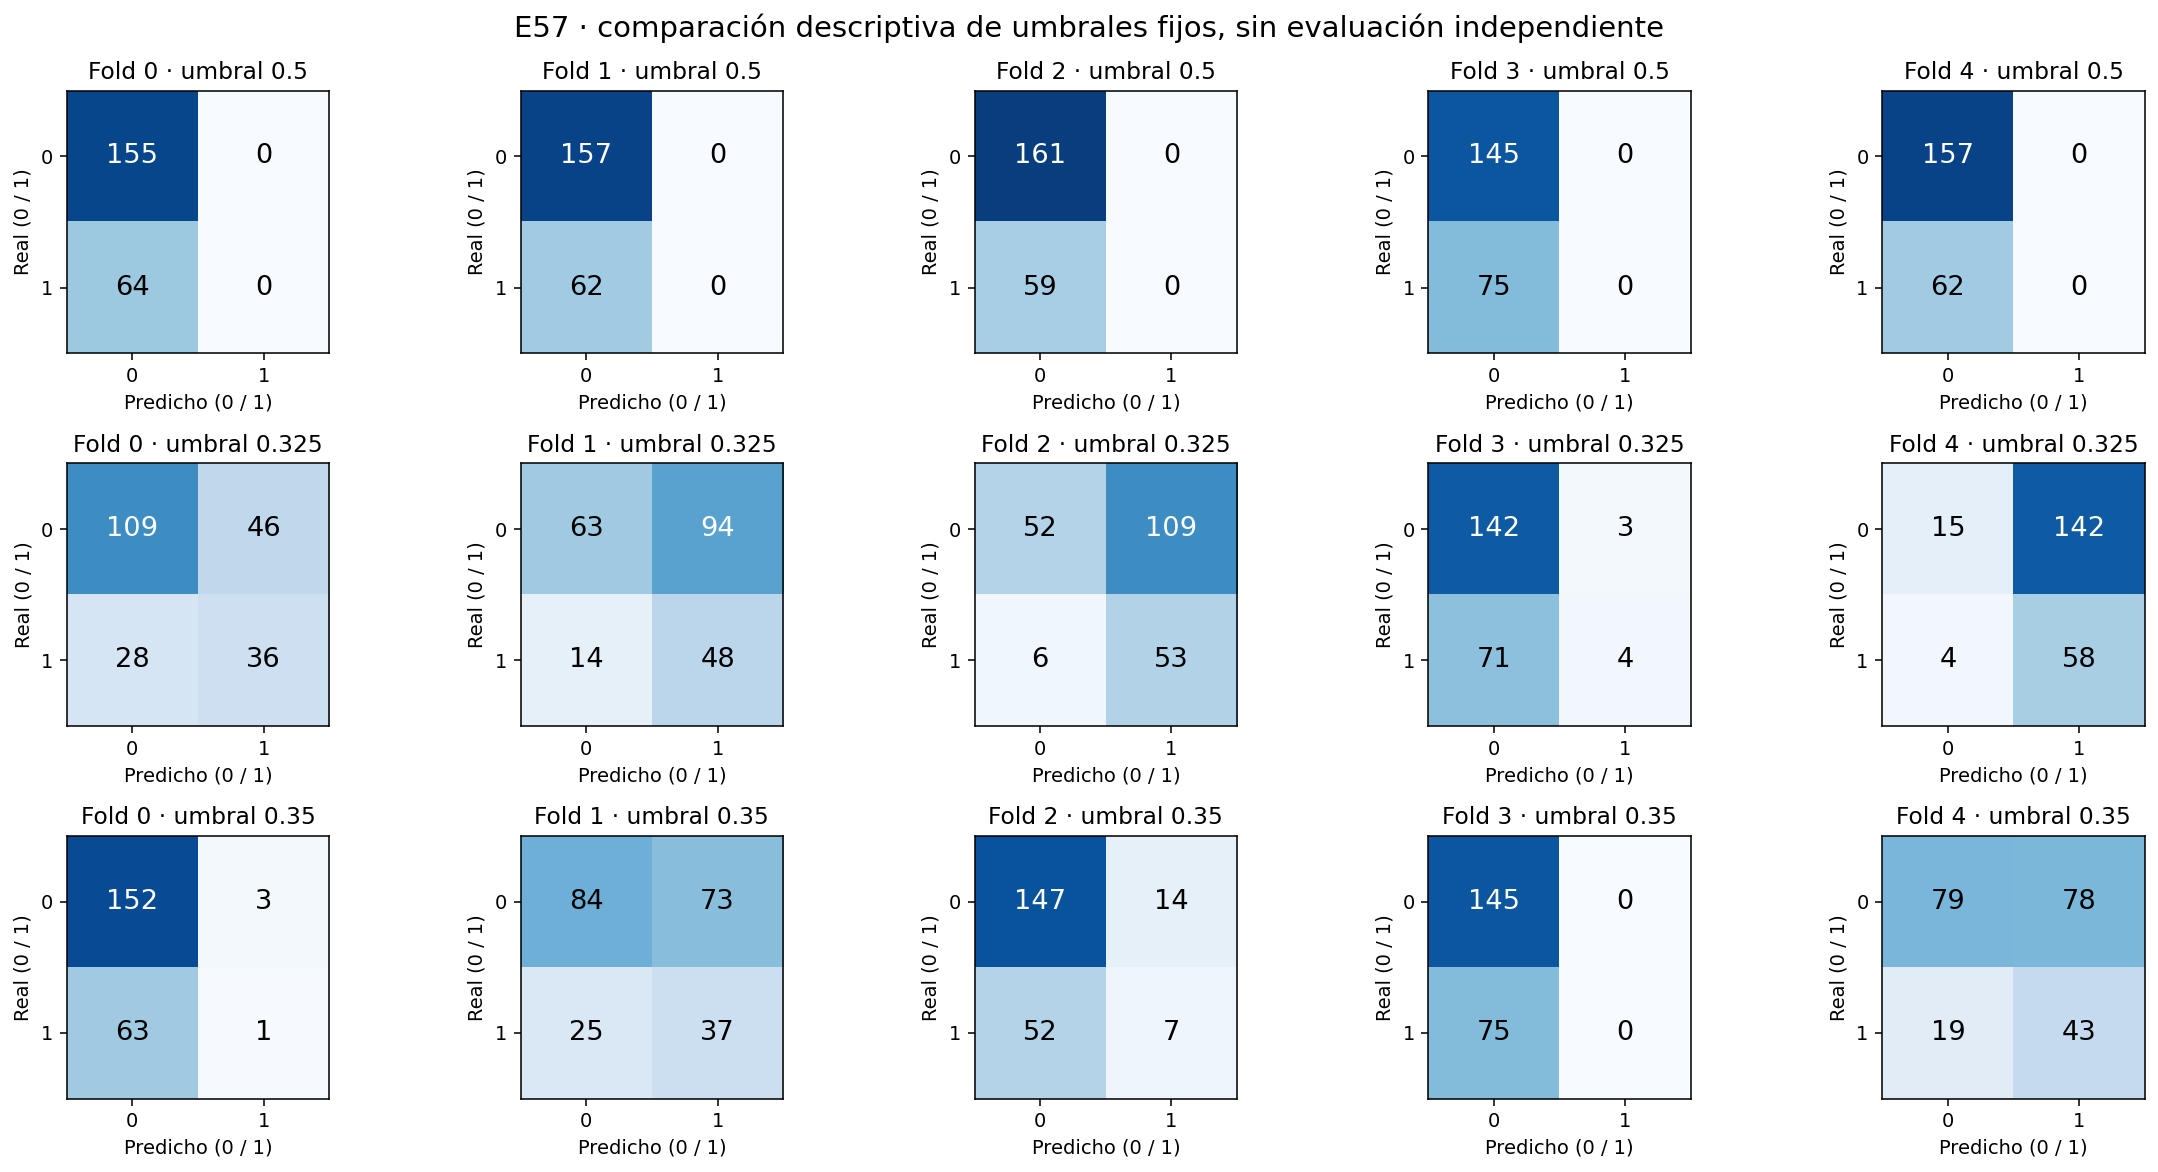

In [1]:
# Matrices con umbrales fijos: comparación descriptiva
# Imagen guardada; visible sin ejecutar esta celda.
